# Next-Season WAR Model: Pitchers

In [18]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import ElasticNet

RANDOM_STATE = 42

## Data Prep

In [19]:
url = "https://raw.githubusercontent.com/Owen-StOnge/IST707PROJECT/main/DataCollectandClean/FinalProject.parquet"
pitchers = pd.read_parquet(url)

pitchers = pitchers.sort_values(["xMLBAMID", "Season"])
g = pitchers.groupby("xMLBAMID")

consecutive = g["Season"].shift(-1) == pitchers["Season"] + 1
pitchers["next_war"] = g["WAR"].shift(-1).where(consecutive)
pitchers["next_money"] = g["Dollars"].shift(-1).where(consecutive)

In [20]:
predictors = ['Age', 'ERA', 'WHIP', 'GB%', 'FIP', 'WAR', 'Zone%', 'K%', 'BB%',
              'Barrel%', 'FBv', 'sp_stuff']

#Keep pitchers with at least 5 starts
starters = pitchers[pitchers['GS'] >= 5].copy()

#Standardize every predictor within season (z-score relative to that season's starters)
starters[predictors] = starters.groupby('Season')[predictors].transform(
    lambda x: (x - x.mean()) / x.std())


#Modeling sample: drop rows with no next-season WAR
model_df = starters.dropna(subset=['next_war']).copy()

X = model_df[predictors].copy()
y = model_df['next_war'].copy()
groups = model_df['xMLBAMID'].copy()

print(f'Modeling rows: {len(model_df)}, Unique pitchers: {groups.nunique()}')

Modeling rows: 2253, Unique pitchers: 722


## Group Train/Test Split (no pitcher in both sets)

In [21]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(len(X_train))
print(len(X_test))
print('Pitchers in both sets:', len(set(groups_train) & set(groups_test)))

1791
462
Pitchers in both sets: 0


## Preprocessing

In [22]:
median_cols = [c for c in predictors if c != 'FBv']

preprocess = ColumnTransformer([
    ('median', SimpleImputer(strategy='median'), median_cols),
    ('fbv', SimpleImputer(strategy='constant', fill_value=0), ['FBv']),
])

#Group-aware CV folds: a pitcher's seasons all land in the same fold
gkf = GroupKFold(n_splits=5)

## Baseline (predict the training mean)

In [23]:
full_pipeline_dummy = make_pipeline(clone(preprocess), DummyRegressor(strategy='mean'))

scores_dummy = -cross_val_score(full_pipeline_dummy, X_train, y_train, groups=groups_train,
                                cv=gkf, scoring='neg_root_mean_squared_error')

print(f'Baseline CV RMSE: mean={scores_dummy.mean():.4f} std={scores_dummy.std():.4f}')

Baseline CV RMSE: mean=1.5471 std=0.1115


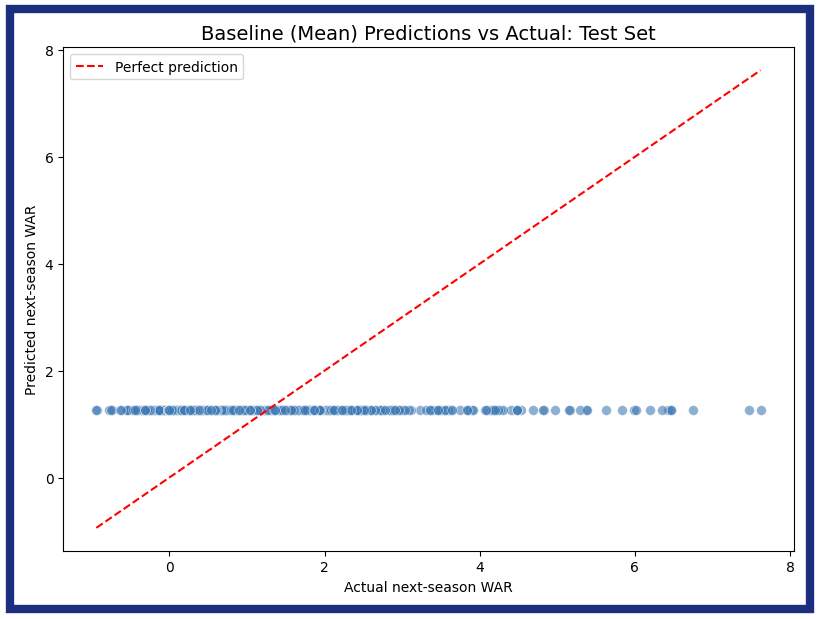

In [32]:
from matplotlib.patches import Rectangle

NAVY = '#1B2F7E'
POINT_BLUE = '#3F7AB5'

def add_border(fig, color=NAVY, width=6):
    fig.patches.append(Rectangle((0, 0), 1, 1, transform=fig.transFigure,
                                 fill=False, edgecolor=color, linewidth=width, zorder=10))

full_pipeline_dummy.fit(X_train, y_train)
y_pred_dummy = full_pipeline_dummy.predict(X_test)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_dummy, color=POINT_BLUE, alpha=0.6,
           edgecolors='white', linewidths=0.5, s=50)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
ax.set_xlabel('Actual next-season WAR')
ax.set_ylabel('Predicted next-season WAR')
ax.set_title('Baseline (Mean) Predictions vs Actual: Test Set', fontsize=14)
ax.legend()
add_border(fig)
plt.tight_layout()
plt.show()

## Decision Tree

In [24]:
full_pipeline_dt = make_pipeline(clone(preprocess), DecisionTreeRegressor(random_state=RANDOM_STATE))

scores_dt = -cross_val_score(full_pipeline_dt, X_train, y_train, groups=groups_train,
                             cv=gkf, scoring='neg_root_mean_squared_error')

print(f'Decision Tree CV RMSE: mean={scores_dt.mean():.4f} std={scores_dt.std():.4f}')

Decision Tree CV RMSE: mean=1.8258 std=0.0622


## Gradient Boosting (minor tuning)

In [25]:
full_pipeline_gb = make_pipeline(clone(preprocess), GradientBoostingRegressor(random_state=RANDOM_STATE))

param_grid_gb = {
    'gradientboostingregressor__n_estimators': [100, 300],
    'gradientboostingregressor__learning_rate': [0.05, 0.1],
    'gradientboostingregressor__max_depth': [2, 3],
}

grid_gb = GridSearchCV(full_pipeline_gb, param_grid_gb, cv=gkf,
                       scoring='neg_root_mean_squared_error')
grid_gb.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", grid_gb.best_params_)
print("Best CV RMSE:", -grid_gb.best_score_)

Best parameters: {'gradientboostingregressor__learning_rate': 0.05, 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__n_estimators': 100}
Best CV RMSE: 1.2963797053115826


## Elastic Net (tuned)

In [26]:
full_pipeline_en = make_pipeline(clone(preprocess), ElasticNet(max_iter=10000))

param_grid_en = {
    'elasticnet__alpha': np.logspace(-3, 1, 20),
    'elasticnet__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
}

grid_en = GridSearchCV(full_pipeline_en, param_grid_en, cv=gkf,
                       scoring='neg_root_mean_squared_error')
grid_en.fit(X_train, y_train, groups=groups_train)

print("Best parameters:", grid_en.best_params_)
print("Best CV RMSE:", -grid_en.best_score_)

Best parameters: {'elasticnet__alpha': np.float64(0.0069519279617756054), 'elasticnet__l1_ratio': 0.7}
Best CV RMSE: 1.2710429467669067


## CV RMSE Comparison

In [27]:
results_df = pd.DataFrame({
    'Model': ['Baseline (mean)', 'Decision Tree', 'Gradient Boosting (tuned)', 'Elastic Net (tuned)'],
    'CV RMSE Mean': [scores_dummy.mean(), scores_dt.mean(),
                     -grid_gb.best_score_, -grid_en.best_score_],
    'CV RMSE Std': [scores_dummy.std(), scores_dt.std(),
                    grid_gb.cv_results_['std_test_score'][grid_gb.best_index_],
                    grid_en.cv_results_['std_test_score'][grid_en.best_index_]],
})
results_df.sort_values('CV RMSE Mean')

,Model,CV RMSE Mean,CV RMSE Std
3,Elastic Net (tuned),1.271043,0.066248
2,Gradient Boosting (tuned),1.296380,0.066147
0,Baseline (mean),1.547100,0.111458
1,Decision Tree,1.825790,0.062209


                       Model  Train RMSE  Test RMSE
0            Baseline (mean)      1.5505     1.5927
1              Decision Tree      0.0000     1.9172
2  Gradient Boosting (tuned)      1.2013     1.2993
3        Elastic Net (tuned)      1.2619     1.3048


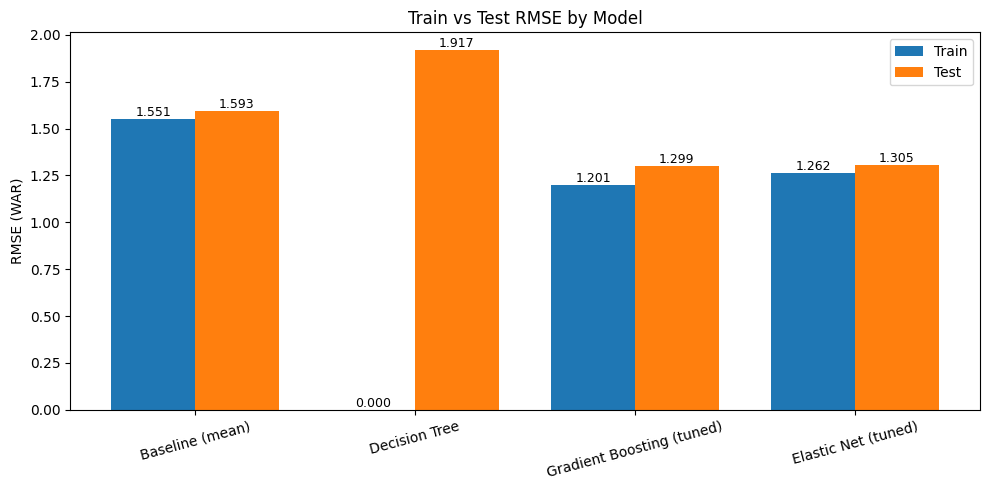

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

#Fit the untuned pipelines on the full training set
full_pipeline_dummy.fit(X_train, y_train)
full_pipeline_dt.fit(X_train, y_train)

final_models = {
    'Baseline (mean)': full_pipeline_dummy,
    'Decision Tree': full_pipeline_dt,
    'Gradient Boosting (tuned)': grid_gb.best_estimator_,
    'Elastic Net (tuned)': grid_en.best_estimator_,
}

rmse_df = pd.DataFrame({
    'Model': list(final_models.keys()),
    'Train RMSE': [root_mean_squared_error(y_train, m.predict(X_train)) for m in final_models.values()],
    'Test RMSE': [root_mean_squared_error(y_test, m.predict(X_test)) for m in final_models.values()],
})
print(rmse_df.round(4))

#Grouped bar chart
x = np.arange(len(rmse_df))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
train_bars = ax.bar(x - width/2, rmse_df['Train RMSE'], width, label='Train')
test_bars = ax.bar(x + width/2, rmse_df['Test RMSE'], width, label='Test')
ax.bar_label(train_bars, fmt='%.3f', fontsize=9)
ax.bar_label(test_bars, fmt='%.3f', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(rmse_df['Model'], rotation=15)
ax.set_ylabel('RMSE (WAR)')
ax.set_title('Train vs Test RMSE by Model')
ax.legend()
plt.tight_layout()
plt.show()

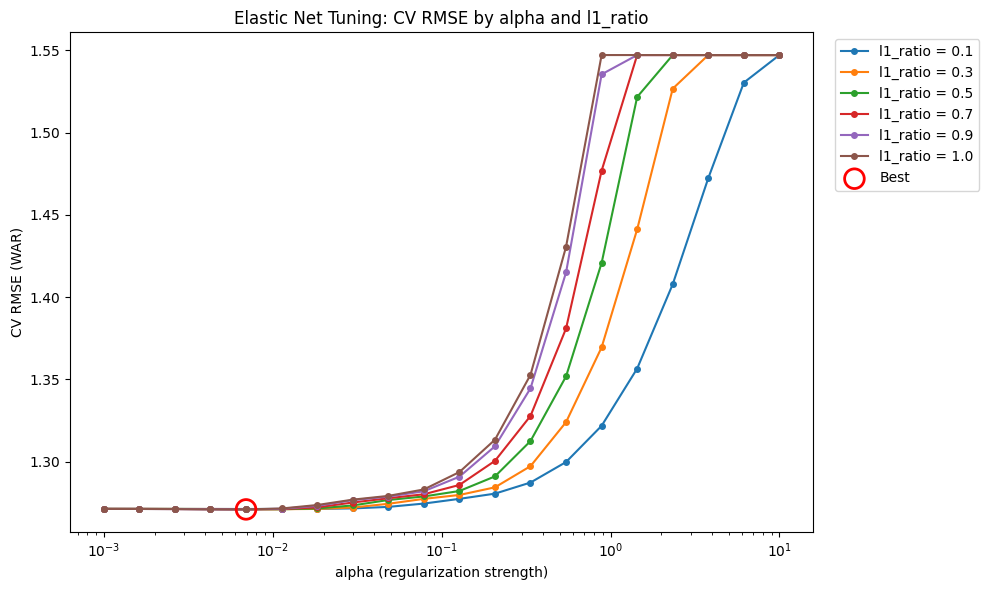

In [29]:

cv_res = pd.DataFrame(grid_en.cv_results_)
cv_res['alpha'] = cv_res['param_elasticnet__alpha'].astype(float)
cv_res['l1_ratio'] = cv_res['param_elasticnet__l1_ratio'].astype(float)
cv_res['cv_rmse'] = -cv_res['mean_test_score']

best_alpha = grid_en.best_params_['elasticnet__alpha']
best_l1 = grid_en.best_params_['elasticnet__l1_ratio']

plt.figure(figsize=(10, 6))
for l1, sub in cv_res.groupby('l1_ratio'):
    sub = sub.sort_values('alpha')
    plt.plot(sub['alpha'], sub['cv_rmse'], marker='o', markersize=4, label=f'l1_ratio = {l1}')
plt.scatter(best_alpha, -grid_en.best_score_, s=200, facecolors='none',
            edgecolors='red', linewidths=2, zorder=5, label='Best')
plt.xscale('log')
plt.xlabel('alpha (regularization strength)')
plt.ylabel('CV RMSE (WAR)')
plt.title('Elastic Net Tuning: CV RMSE by alpha and l1_ratio')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

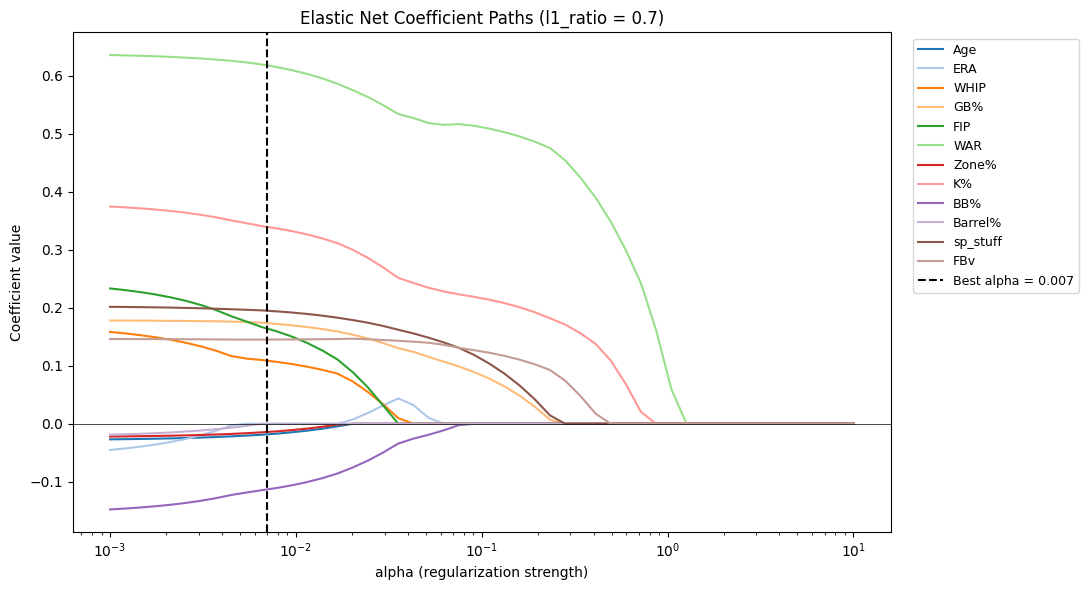

In [30]:
best_en = grid_en.best_estimator_
X_train_prep = best_en.named_steps['columntransformer'].transform(X_train)
feature_names = [n.split('__')[-1] for n in
                 best_en.named_steps['columntransformer'].get_feature_names_out()]

alpha_range = np.logspace(-3, 1, 50)
coefs = []
for a in alpha_range:
    en = ElasticNet(alpha=a, l1_ratio=best_l1, max_iter=10000)
    en.fit(X_train_prep, y_train)
    coefs.append(en.coef_)
coefs = np.array(coefs)

plt.figure(figsize=(11, 6))
for i in range(coefs.shape[1]):
    plt.plot(alpha_range, coefs[:, i], label=feature_names[i], color=plt.cm.tab20(i))
plt.axvline(best_alpha, color='black', linestyle='--', label=f'Best alpha = {best_alpha:.3f}')
plt.axhline(0, color='black', linewidth=0.5)
plt.xscale('log')
plt.xlabel('alpha (regularization strength)')
plt.ylabel('Coefficient value')
plt.title(f'Elastic Net Coefficient Paths (l1_ratio = {best_l1})')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

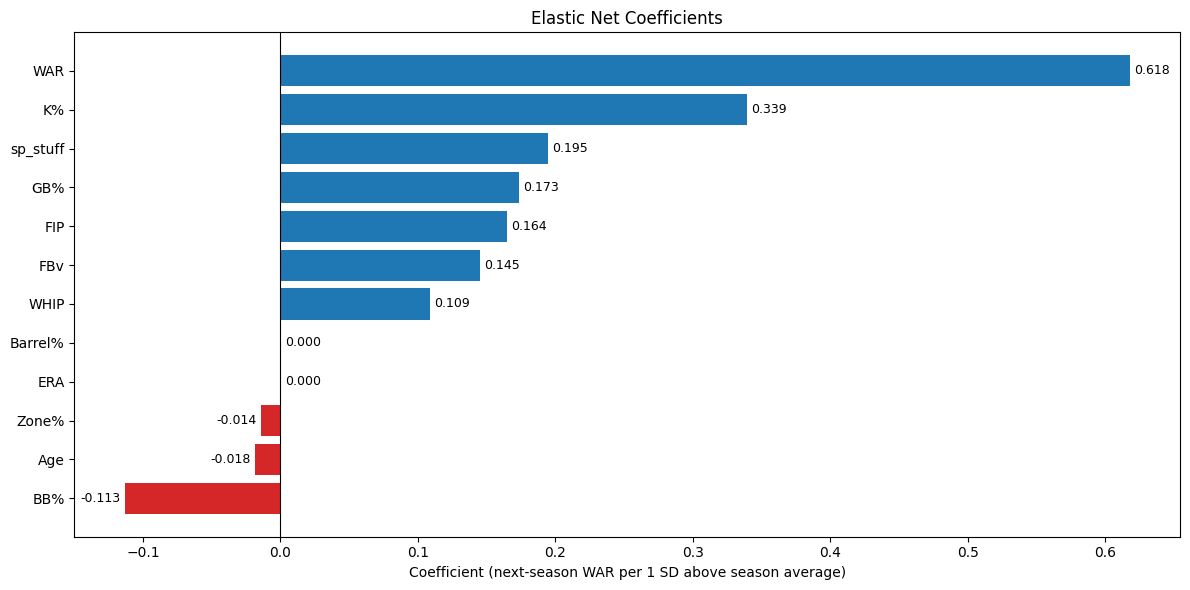

Intercept: 1.196
Features dropped to 0: ['ERA', 'Barrel%']


In [31]:
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': best_en.named_steps['elasticnet'].coef_,
}).sort_values('Coefficient')

colors = ['tab:red' if c < 0 else 'tab:blue' for c in coef_df['Coefficient']]

plt.figure(figsize=(12, 6))
bars = plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coefficient (next-season WAR per 1 SD above season average)')
plt.title('Elastic Net Coefficients')
plt.tight_layout()
plt.show()

print('Intercept:', round(best_en.named_steps['elasticnet'].intercept_, 3))
print('Features dropped to 0:', list(coef_df.loc[coef_df['Coefficient'] == 0, 'Feature']))

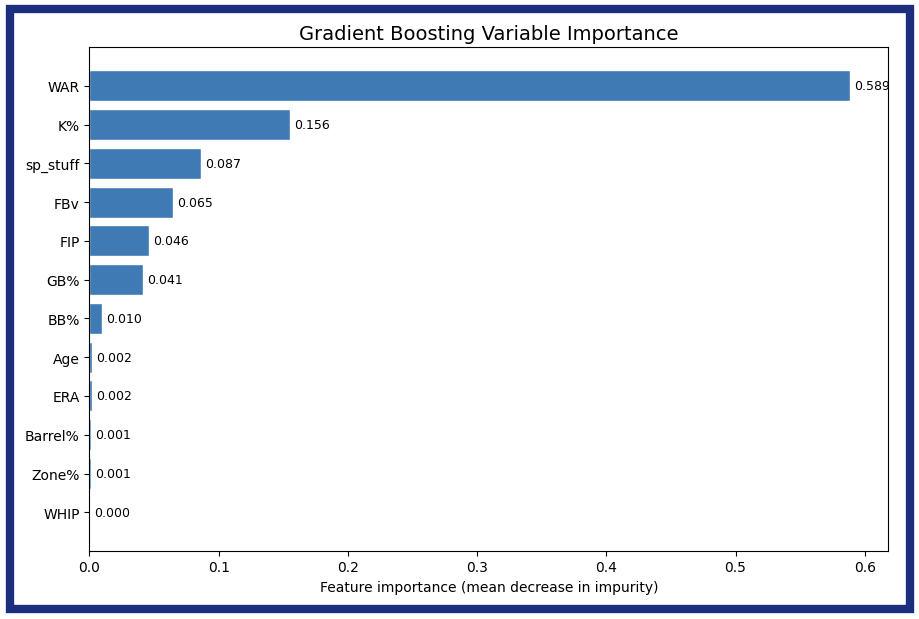

In [34]:
best_gb = grid_gb.best_estimator_
gb_names = [n.split('__')[-1] for n in
            best_gb.named_steps['columntransformer'].get_feature_names_out()]

gb_imp = pd.Series(best_gb.named_steps['gradientboostingregressor'].feature_importances_,
                   index=gb_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(gb_imp.index, gb_imp.values, color=POINT_BLUE, edgecolor='white')
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_xlabel('Feature importance (mean decrease in impurity)')
ax.set_title('Gradient Boosting Variable Importance', fontsize=14)
add_border(fig)
plt.tight_layout()
plt.show()

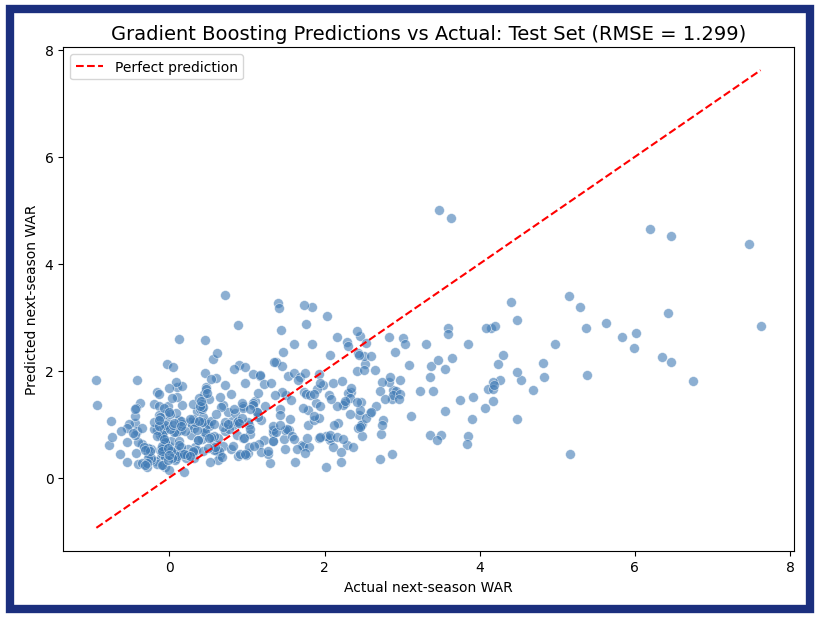

In [36]:
best_gb = grid_gb.best_estimator_
y_pred_gb = best_gb.predict(X_test)
gb_test_rmse = root_mean_squared_error(y_test, y_pred_gb)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred_gb, color=POINT_BLUE, alpha=0.6,
           edgecolors='white', linewidths=0.5, s=50)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect prediction')
ax.set_xlabel('Actual next-season WAR')
ax.set_ylabel('Predicted next-season WAR')
ax.set_title(f'Gradient Boosting Predictions vs Actual: Test Set (RMSE = {gb_test_rmse:.3f})', fontsize=14)
ax.legend()
add_border(fig)
plt.tight_layout()
plt.show()

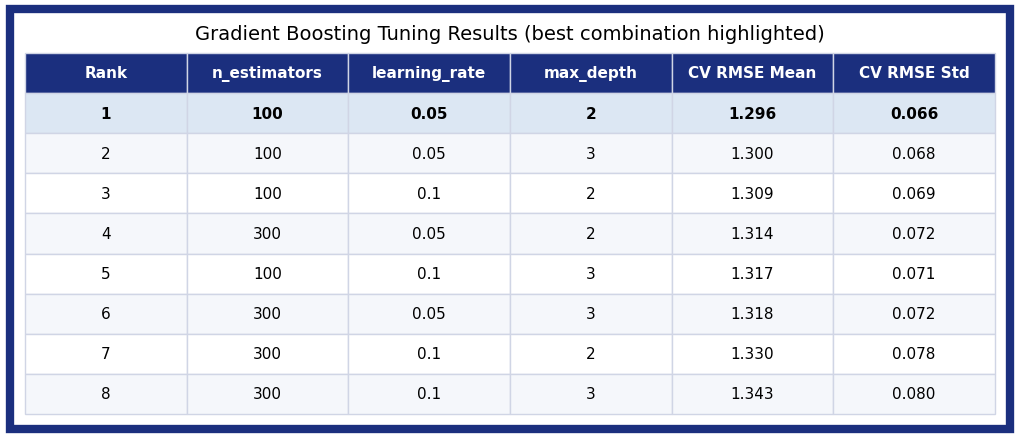

In [35]:
gb_res = pd.DataFrame(grid_gb.cv_results_)

gb_table = pd.DataFrame({
    'Rank': gb_res['rank_test_score'],
    'n_estimators': gb_res['param_gradientboostingregressor__n_estimators'].astype(int),
    'learning_rate': gb_res['param_gradientboostingregressor__learning_rate'].astype(float),
    'max_depth': gb_res['param_gradientboostingregressor__max_depth'].astype(int),
    'CV RMSE Mean': (-gb_res['mean_test_score']).round(3),
    'CV RMSE Std': gb_res['std_test_score'].round(3),
}).sort_values('Rank').reset_index(drop=True)

cell_text = gb_table.assign(**{
    'CV RMSE Mean': gb_table['CV RMSE Mean'].map('{:.3f}'.format),
    'CV RMSE Std': gb_table['CV RMSE Std'].map('{:.3f}'.format),
}).astype(str).values

fig, ax = plt.subplots(figsize=(10, 0.4 * len(gb_table) + 1))
ax.axis('off')

tbl = ax.table(cellText=cell_text, colLabels=gb_table.columns,
               cellLoc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('#D0D5E5')
    if row == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(color='white', weight='bold')
    elif row == 1:
        cell.set_facecolor('#DCE7F3')
        cell.set_text_props(weight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#F5F7FB')

ax.set_title('Gradient Boosting Tuning Results (best combination highlighted)', fontsize=14, pad=10)
add_border(fig)
plt.tight_layout()
plt.show()